In [1]:
import os
import glob
import cv2
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

In [ ]:
#1
def carregar_dados_bsds(id_imagem):
    dir_base = os.path.join("archive")

    img_path = os.path.join(dir_base, "images", "train", f"{id_imagem}.jpg")
    mat_path = os.path.join(dir_base, "ground_truth", "train", f"{id_imagem}.mat")

    print(f"-> Procurando imagem em: {img_path}")
    print(f"-> Procurando matriz em: {mat_path}")

    if not os.path.exists(img_path):
        raise FileNotFoundError(f"A IMAGEM não foi encontrada no caminho: {img_path}")

    if not os.path.exists(mat_path):
        raise FileNotFoundError(f"O ARQUIVO .MAT não foi encontrado no caminho: {mat_path}")

    imagem = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    mat = sio.loadmat(mat_path)
    borda_gt = mat["groundTruth"][0, 0]["Boundaries"][0, 0]
    borda_gt_img = (borda_gt * 255).astype(np.uint8)

    return imagem, borda_gt_img


def mostrar_dados(dados_treino):
    import ipywidgets as widgets
    from IPython.display import display

    indice = 0
    saida = widgets.Output()

    botao_anterior = widgets.Button(description="← Anterior")
    botao_proximo = widgets.Button(description="Próxima →")

    def atualizar():
        id_imagem, imagem, gt = dados_treino[indice]

        with saida:
            saida.clear_output(wait=True)

            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

            ax1.imshow(imagem, cmap="gray")
            ax2.imshow(gt, cmap="gray")

            ax1.set_title(f"Imagem Original ({id_imagem})")
            ax2.set_title("Ground Truth (Bordas Reais)")

            fig.suptitle(
                f"Imagem {indice + 1}/{len(dados_treino)} - use os botões para navegar"
            )

            plt.tight_layout()
            plt.show()
            plt.close(fig)

    def anterior(_):
        nonlocal indice
        indice = (indice - 1) % len(dados_treino)
        atualizar()

    def proximo(_):
        nonlocal indice
        indice = (indice + 1) % len(dados_treino)
        atualizar()

    botao_anterior.on_click(anterior)
    botao_proximo.on_click(proximo)

    display(widgets.HBox([botao_anterior, botao_proximo]))
    display(saida)

    atualizar()


if __name__ == "__main__":
    pasta_imagens = os.path.join("archive", "images", "train")
    imagens_disponiveis = sorted(glob.glob(os.path.join(pasta_imagens, "*.jpg")))

    if not imagens_disponiveis:
        print(f"Não há nenhuma imagem na pasta: {pasta_imagens}")
    else:
        dados_treino = []
        for img_path in imagens_disponiveis:
            id_imagem = os.path.splitext(os.path.basename(img_path))[0]
            imagem, gt = carregar_dados_bsds(id_imagem)
            dados_treino.append((id_imagem, imagem, gt))

        print(f"Foram carregados {len(dados_treino)} pares de imagem e ground truth.")
        mostrar_dados(dados_treino)



-> Procurando imagem em: archive/images/train/100075.jpg
-> Procurando matriz em: archive/ground_truth/train/100075.mat
-> Procurando imagem em: archive/images/train/100080.jpg
-> Procurando matriz em: archive/ground_truth/train/100080.mat
-> Procurando imagem em: archive/images/train/100098.jpg
-> Procurando matriz em: archive/ground_truth/train/100098.mat
-> Procurando imagem em: archive/images/train/103041.jpg
-> Procurando matriz em: archive/ground_truth/train/103041.mat
-> Procurando imagem em: archive/images/train/104022.jpg
-> Procurando matriz em: archive/ground_truth/train/104022.mat
-> Procurando imagem em: archive/images/train/105019.jpg
-> Procurando matriz em: archive/ground_truth/train/105019.mat
-> Procurando imagem em: archive/images/train/105053.jpg
-> Procurando matriz em: archive/ground_truth/train/105053.mat
-> Procurando imagem em: archive/images/train/106020.jpg
-> Procurando matriz em: archive/ground_truth/train/106020.mat
-> Procurando imagem em: archive/images/

Output()

In [ ]:
#2
def detectar_canny(imagem):
    return cv2.Canny(imagem, 100, 200)


def detectar_sobel(imagem):
    gx = cv2.Sobel(imagem, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(imagem, cv2.CV_64F, 0, 1, ksize=3)
    magnitude = cv2.magnitude(gx, gy)
    _, bordas = cv2.threshold(magnitude, 100, 255, cv2.THRESH_BINARY)
    return bordas.astype(np.uint8)


def detectar_prewitt(imagem):
    kernel_x = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ])

    kernel_y = np.array([
        [-1, -1, -1],
        [0, 0, 0],
        [1, 1, 1]
    ])

    gx = cv2.filter2D(imagem, cv2.CV_32F, kernel_x)
    gy = cv2.filter2D(imagem, cv2.CV_32F, kernel_y)
    magnitude = cv2.magnitude(gx, gy)
    _, bordas = cv2.threshold(magnitude, 100, 255, cv2.THRESH_BINARY)
    return bordas.astype(np.uint8)


def detectar_roberts(imagem):
    kernel_x = np.array([
        [1, 0],
        [0, -1]
    ])

    kernel_y = np.array([
        [0, 1],
        [-1, 0]
    ])

    gx = cv2.filter2D(imagem, cv2.CV_32F, kernel_x)
    gy = cv2.filter2D(imagem, cv2.CV_32F, kernel_y)
    magnitude = cv2.magnitude(gx, gy)
    _, bordas = cv2.threshold(magnitude, 100, 255, cv2.THRESH_BINARY)
    return bordas.astype(np.uint8)


operadores = {
    "Canny": detectar_canny,
    "Sobel": detectar_sobel,
    "Prewitt": detectar_prewitt,
    "Roberts": detectar_roberts
}


def mostrar_operadores(dados_treino):
    import ipywidgets as widgets
    from IPython.display import display

    indice = 0
    saida = widgets.Output()

    anterior = widgets.Button(description="← Anterior")
    proximo = widgets.Button(description="Próxima →")
    posicao = widgets.Label()

    def atualizar():
        id_imagem, imagem, gt = dados_treino[indice]

        posicao.value = f"Imagem {indice + 1}/{len(dados_treino)}"

        with saida:
            saida.clear_output(wait=True)

            fig, axes = plt.subplots(2, 3, figsize=(14, 8))

            resultados = {
                "Imagem Original": imagem,
                "Ground Truth": gt
            }

            for nome, funcao in operadores.items():
                resultados[nome] = funcao(imagem)

            for ax, (nome, resultado) in zip(axes.flat, resultados.items()):
                ax.imshow(resultado, cmap="gray")
                ax.set_title(nome)
                ax.axis("off")

            fig.suptitle(f"Comparação dos Operadores - Imagem {id_imagem}")

            plt.tight_layout()
            plt.show()
            plt.close(fig)

    def voltar(_):
        nonlocal indice
        indice = (indice - 1) % len(dados_treino)
        atualizar()

    def avancar(_):
        nonlocal indice
        indice = (indice + 1) % len(dados_treino)
        atualizar()

    anterior.on_click(voltar)
    proximo.on_click(avancar)

    display(widgets.HBox([anterior, posicao, proximo]))
    display(saida)

    atualizar()


mostrar_operadores(dados_treino)


Output()

RESULTADOS DOS OPERADORES

Canny
Precisão: 0.0364
Sensibilidade (Recall): 0.2757

Sobel
Precisão: 0.0383
Sensibilidade (Recall): 0.5499

Prewitt
Precisão: 0.0449
Sensibilidade (Recall): 0.4495

Roberts
Precisão: 0.0443
Sensibilidade (Recall): 0.0596



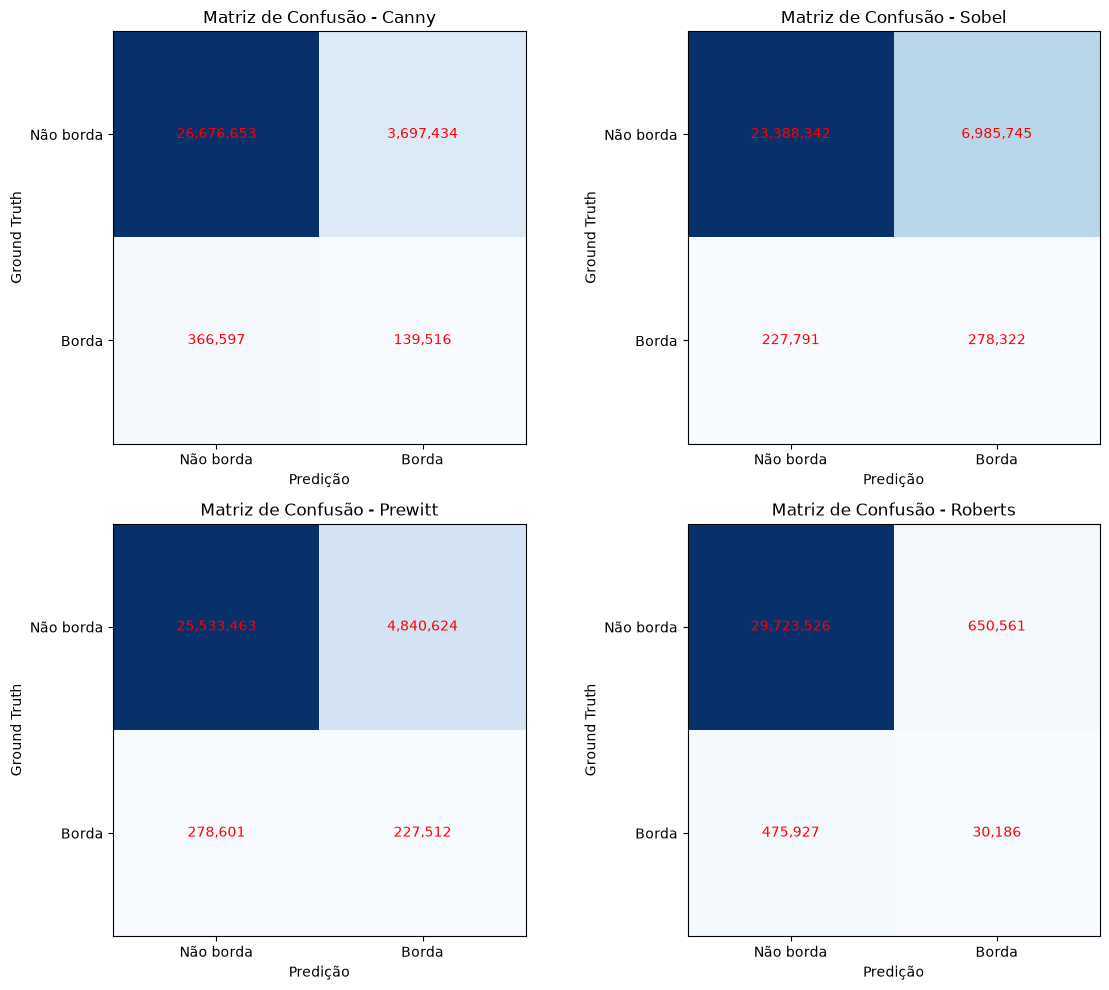

In [4]:
#3
matrizes = {}
metricas = {}

for nome, funcao in operadores.items():
    tn = fp = fn = tp = 0

    for id_imagem, imagem, gt in dados_treino:
        resultado = funcao(imagem)

        predicao = resultado > 0
        referencia = gt > 0

        tp += np.sum(predicao & referencia)
        fp += np.sum(predicao & ~referencia)
        fn += np.sum(~predicao & referencia)
        tn += np.sum(~predicao & ~referencia)

    matriz = np.array([
        [tn, fp],
        [fn, tp]
    ])

    precisao = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    matrizes[nome] = matriz
    metricas[nome] = [precisao, recall]


print("RESULTADOS DOS OPERADORES\n")

for nome, valores in metricas.items():
    print(f"{nome}")
    print(f"Precisão: {valores[0]:.4f}")
    print(f"Sensibilidade (Recall): {valores[1]:.4f}")
    print()


fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (nome, matriz) in zip(axes.flat, matrizes.items()):
    ax.imshow(matriz, cmap="Blues")
    ax.set_title(f"Matriz de Confusão - {nome}")
    ax.set_xlabel("Predição")
    ax.set_ylabel("Ground Truth")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Não borda", "Borda"])
    ax.set_yticklabels(["Não borda", "Borda"])

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{matriz[i, j]:,}",
                ha="center", va="center", color="red"
            )

plt.tight_layout()
plt.show()
